# PINN V5 - Notebook
Script complet pour entraîner le PINN avec estimation de $D_v$, $\alpha$ et $n$

🚀 Starting training with time-dependent parameters...
✅ Profile 1/3 accepted. Loss = 1.9565e+00
✅ Profile 2/3 accepted. Loss = 4.8664e-01
✅ Profile 3/3 accepted. Loss = 8.0178e-01
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros

📉 Epoch 0, Loss: 1.0816e+00
   Mean values: D=4.24e-08, α=0.0913, n=4.31


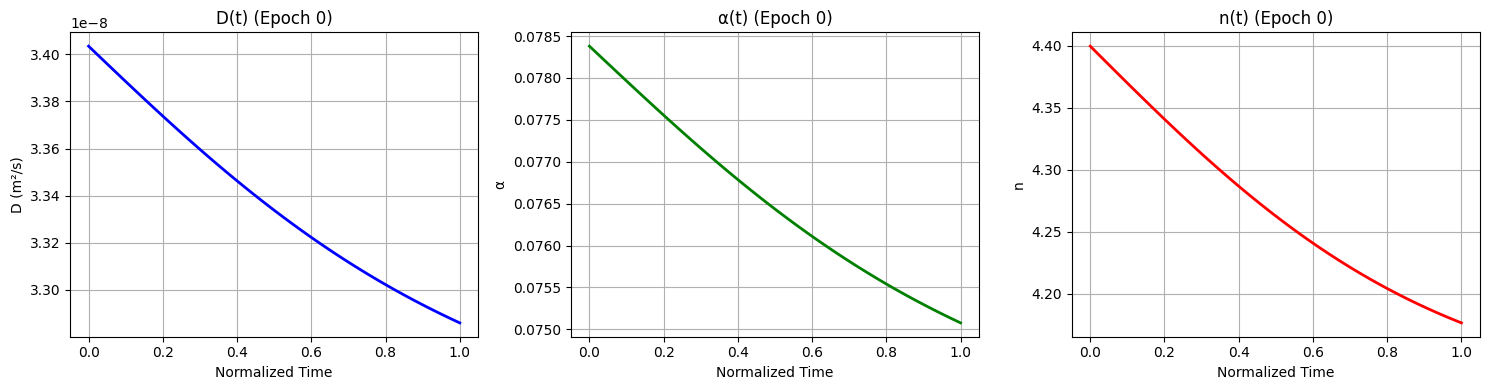

✅ Profile 1/3 accepted. Loss = 1.9565e+00
✅ Profile 2/3 accepted. Loss = 4.8664e-01
✅ Profile 3/3 accepted. Loss = 8.0178e-01
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
⚠️ NaN in gradients, replaced with zeros
✅ Profile 1/3 accepted. Loss = 1.9565e+00
✅ Profile 2/3 accepted. Loss = 4.8664e-01
✅ Profile 3/3 accepted. Loss = 8.0178e-01
⚠️ NaN in 

KeyboardInterrupt: 

In [12]:
# 🔁 Version V6 - PINN with time-dependent D(t), α(t), and n(t)

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# 📥 Charger le dataset
df_all = pd.read_csv("Dataset_multi-temps_format_.csv")

# 📊 Calcul automatique des moyennes et écarts-types
input_columns = ['phi', 'T', 'w_c', 'S0', 't_h']
X_all = df_all[input_columns].drop_duplicates().values.astype(np.float32)
X_mean = tf.constant(np.mean(X_all, axis=0), dtype=tf.float32)
X_std = tf.constant(np.std(X_all, axis=0), dtype=tf.float32)
X_std_safe = tf.where(X_std == 0.0, tf.ones_like(X_std), X_std)

# === 2. Normalisation ===
def normalize(x):
    return (x - X_mean) / X_std_safe

# === 3. Time-dependent parameter networks ===
def build_time_param_network(name, output_range):
    """
    Build a small network that takes normalized time as input and outputs a parameter value
    output_range: tuple (min_val, max_val) for the parameter
    """
    model = Sequential([
        Input(shape=(1,), name=f"{name}_time_input"),
        Dense(16, activation='tanh', name=f"{name}_hidden1"),
        Dense(16, activation='tanh', name=f"{name}_hidden2"),
        Dense(1, activation='linear', name=f"{name}_raw_output")
    ], name=f"{name}_network")
    return model, output_range

# Create time-dependent networks for D, α, and n
D_network, D_range = build_time_param_network("D", (1e-9, 1e-7))
alpha_network, alpha_range = build_time_param_network("alpha", (0.005, 0.15))
n_network, n_range = build_time_param_network("n", (1.2, 8.0))

# === 4. Main model that outputs base scaling factors ===
def build_main_model(input_dim=5):
    """
    Main model that takes material properties and outputs base scaling factors
    for the time-dependent parameters
    """
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(20, activation='tanh'),
        Dense(20, activation='tanh'),
        Dense(3, activation='linear')  # 3 outputs: base scales for D, α, n
    ], name="main_model")
    return model

main_model = build_main_model()

# === 5. Parameter extraction with time dependence ===
@tf.function
def get_time_dependent_params(t_normalized, base_scales, D_net, alpha_net, n_net):
    """
    Get parameter values at normalized time t
    t_normalized: normalized time in [0, 1]
    base_scales: [D_scale, alpha_scale, n_scale] from main model
    """
    # Ensure t_normalized has proper shape
    t_input = tf.reshape(t_normalized, (-1, 1))
    
    # Get raw outputs from time networks
    D_time_factor = D_net(t_input)
    alpha_time_factor = alpha_net(t_input)
    n_time_factor = n_net(t_input)
    
    # Apply sigmoid to time factors to get values in [0, 1]
    D_time_factor = tf.nn.sigmoid(D_time_factor)
    alpha_time_factor = tf.nn.sigmoid(alpha_time_factor)
    n_time_factor = tf.nn.sigmoid(n_time_factor)
    
    # Extract base scales
    D_scale = base_scales[0:1]
    alpha_scale = base_scales[1:2]
    n_scale = base_scales[2:3]
    
    # Compute final parameters with constraints
    # D: exponential scaling around base value
    D_base = tf.nn.sigmoid(D_scale) * (D_range[1] - D_range[0]) + D_range[0]
    Dv = D_base * tf.exp((D_time_factor - 0.5) * 0.5)  # ±30% variation
    Dv = tf.clip_by_value(Dv, D_range[0], D_range[1])
    
    # α: linear scaling around base value
    alpha_base = tf.nn.sigmoid(alpha_scale) * (alpha_range[1] - alpha_range[0]) + alpha_range[0]
    alpha0 = alpha_base * (0.7 + 0.6 * D_time_factor)  # 70% to 130% of base
    alpha0 = tf.clip_by_value(alpha0, alpha_range[0], alpha_range[1])
    
    # n: linear scaling around base value
    n_base = tf.nn.sigmoid(n_scale) * (n_range[1] - n_range[0]) + n_range[0]
    nShape = n_base * (0.8 + 0.4 * n_time_factor)  # 80% to 120% of base
    nShape = tf.clip_by_value(nShape, n_range[0], n_range[1])
    
    return tf.squeeze(Dv), tf.squeeze(alpha0), tf.squeeze(nShape)

# === 6. Modified simulation with time-dependent parameters ===
@tf.function
def simulate_model_tf_time_dependent(base_scales, D_net, alpha_net, n_net, 
                                    S0, phi, rho_eau, dx, dt, Tmax, Nx, mode="imbibition"):
    """
    Simulation with time-dependent parameters
    """
    # Convert scalars to tensors
    dx = tf.convert_to_tensor(dx, dtype=tf.float32)
    dt = tf.convert_to_tensor(dt, dtype=tf.float32)
    Tmax = tf.convert_to_tensor(Tmax, dtype=tf.float32)
    Nx = tf.convert_to_tensor(Nx, dtype=tf.int32)

    Nt = tf.cast(tf.math.floordiv(Tmax, dt), tf.int32)
    x_vals = tf.linspace(0.0, dx * tf.cast(Nx - 1, tf.float32), Nx)

    # Physical parameters
    Sc = 0.8
    S_cap = 0.75
    beta = 2.5
    Pc0 = 5e6
    K_in = 1.7e-20
    eta_l = 1e-3

    # Initialize saturation
    if mode == "imbibition":
        S = tf.ones((Nx,), dtype=tf.float32) * 0.01
        S = tf.tensor_scatter_nd_update(S, [[0]], [S0])
    elif mode == "drainage":
        S = tf.ones((Nx,), dtype=tf.float32) * S0
    else:
        raise ValueError("Mode must be 'imbibition' or 'drainage'")

    M = tf.ones((Nx,), dtype=tf.float32) * dx
    M = tf.tensor_scatter_nd_update(M, [[0], [Nx - 1]], [dx / 2, dx / 2])

    # Define diffusion functions outside the loop
    def Dvapeur(S_val, alpha0, nShape, Dv):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        fs = alpha0 + (1.0 - alpha0) / (1.0 + tf.pow((1.0 - S_val) / (1.0 - Sc), nShape))
        return tf.clip_by_value(fs, 1e-12, 10.0) * Dv

    def Dcapi(S_val):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        dpc = -beta * Pc0 * tf.pow(S_val, -beta - 1)
        return tf.abs(dpc) * K_in / eta_l

    def D_S(S_val, alpha0, nShape, Dv):
        weight = tf.math.sigmoid(50.0 * (S_val - S_cap))
        return weight * Dcapi(S_val) + (1.0 - weight) * Dvapeur(S_val, alpha0, nShape, Dv)

    # Time loop with time-dependent parameters
    current_time = tf.constant(0.0)
    
    for i in tf.range(Nt):
        # Normalize time to [0, 1]
        t_normalized = current_time / Tmax
        
        # Get time-dependent parameters
        Dv, alpha0, nShape = get_time_dependent_params(t_normalized, base_scales, 
                                                      D_net, alpha_net, n_net)
        
        S_old = S
        for _ in tf.range(5):  # Picard iterations
            D_vals = D_S(S, alpha0, nShape, Dv)

            D_left = (D_vals[:-1] + D_vals[1:]) / 2.0
            fluxes = D_left * (S[1:] - S[:-1]) / dx

            dS_dt = tf.zeros_like(S)

            # Update interior points
            interior_flux = (fluxes[1:] - fluxes[:-1]) / dx
            dS_dt = tf.tensor_scatter_nd_add(
                dS_dt,
                tf.range(1, Nx - 1)[:, tf.newaxis],
                interior_flux
            )

            # Right boundary: Neumann ≈ 0
            last_flux = fluxes[-1] / dx
            dS_dt = tf.tensor_scatter_nd_add(dS_dt, [[Nx - 1]], [-last_flux])

            # Update S
            S = S_old + dt * dS_dt
            S = tf.tensor_scatter_nd_update(S, [[0]], [S0])  # Dirichlet
        
        # Update time
        current_time = current_time + dt

    w_final = phi * rho_eau * S
    return x_vals, w_final

# === 7. Combined optimizer for all networks ===
all_models = [main_model, D_network, alpha_network, n_network]
optimizer = Adam(learning_rate=1e-3)

# === 8. Modified training function ===
@tf.function
def tf_linear_interp(x_known, y_known, x_interp):
    x_interp_m = x_interp * 1e-3
    indices = tf.searchsorted(x_known, x_interp_m, side='right') - 1
    indices = tf.clip_by_value(indices, 0, tf.shape(x_known)[0] - 2)
    x0 = tf.gather(x_known, indices)
    x1 = tf.gather(x_known, indices + 1)
    y0 = tf.gather(y_known, indices)
    y1 = tf.gather(y_known, indices + 1)
    return y0 + (y1 - y0) * (x_interp_m - x0) / (x1 - x0 + 1e-12)

def train_epoch_time_dependent(all_models, df_all, optimizer, normalize, 
                              simulate_model_tf_time_dependent, tf_linear_interp, 
                              Nx=50, dx=1e-3, dt=30.0):
    
    main_model, D_net, alpha_net, n_net = all_models
    
    unique_inputs = (
        df_all[['phi', 'T', 'w_c', 'S0', 't_h']]
        .round(4)
        .drop_duplicates()
        .values.astype(np.float32)
    )

    total_loss = 0.0
    valid_count = 0
    param_epoch_vals = {'Dv_mean': [], 'alpha_mean': [], 'n_mean': []}

    with tf.GradientTape() as tape:
        for i in range(len(unique_inputs)):
            phi, T, wc, S0, t_h = unique_inputs[i]
            input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            
            norm_input = normalize(input_tensor)
            if tf.reduce_any(tf.math.is_nan(norm_input)):
                print(f"❌ NaN in normalized input for profile {i+1}")
                continue
                
            # Get base scales from main model
            base_scales = main_model(norm_input)[0]
            
            if tf.reduce_any(tf.math.is_nan(base_scales)):
                print(f"❌ NaN in model output for profile {i+1}")
                continue

            # Get experimental data
            phi_f, T_f, wc_f, S0_f, t_h_f = map(float, [phi, T, wc, S0, t_h])
            group = df_all[
                (df_all['phi'].round(4) == round(phi_f, 4)) &
                (df_all['T'] == T_f) &
                (df_all['w_c'].round(4) == round(wc_f, 4)) &
                (df_all['S0'].round(4) == round(S0_f, 4)) &
                (df_all['t_h'] == t_h_f)
            ]

            x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
            w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

            if len(x_exp) < 3:
                print("❌ Too few points for profile:", t_h)
                continue

            w_exp_mean = tf.reduce_mean(w_exp)
            w_exp_std = tf.math.reduce_std(w_exp)
            if tf.math.is_nan(w_exp_std) or w_exp_std < 1e-8:
                print(f"❌ Rejected: std(w_exp) = {w_exp_std.numpy()}")
                continue

            try:
                # Run simulation with time-dependent parameters
                x_model, w_model = simulate_model_tf_time_dependent(
                    base_scales, D_net, alpha_net, n_net,
                    S0, phi, 1000.0, dx, dt, t_h * 3600.0, Nx
                )
                
                if tf.reduce_any(tf.math.is_nan(w_model)):
                    print("❌ NaN in simulation")
                    continue
                    
            except Exception as e:
                print(f"❌ Simulation error: {e}")
                continue
            
            # Interpolate and compute loss
            x_exp_clip = tf.clip_by_value(x_exp * 1e-3, x_model[0], x_model[-1]) * 1e3
            w_interp = tf_linear_interp(x_model, w_model, x_exp_clip)

            w_exp_norm = (w_exp - w_exp_mean) / (w_exp_std + 1e-12)
            w_interp_norm = (w_interp - w_exp_mean) / (w_exp_std + 1e-12)

            if tf.reduce_any(tf.math.is_nan(w_interp_norm)):
                print("❌ Rejected: NaN in w_interp_norm")
                continue

            loss = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
            if tf.math.is_nan(loss):
                print("❌ Rejected: NaN in loss")
                continue

            print(f"✅ Profile {i+1}/{len(unique_inputs)} accepted. Loss = {loss.numpy():.4e}")

            total_loss += loss
            valid_count += 1
            
            # Sample parameters at different times for monitoring
            for t_sample in [0.0, 0.5, 1.0]:
                t_norm = tf.constant(t_sample)
                Dv_t, alpha_t, n_t = get_time_dependent_params(t_norm, base_scales, 
                                                               D_net, alpha_net, n_net)
                param_epoch_vals['Dv_mean'].append(Dv_t.numpy())
                param_epoch_vals['alpha_mean'].append(alpha_t.numpy())
                param_epoch_vals['n_mean'].append(n_t.numpy())

        if valid_count == 0:
            print("❌ No valid profiles → stopping.")
            return None, None

        mean_loss = total_loss / valid_count

    # Compute gradients for all models
    all_variables = []
    for model in all_models:
        all_variables.extend(model.trainable_variables)
    
    grads = tape.gradient(mean_loss, all_variables)
    grads = [tf.clip_by_value(g, -0.5, 0.5) if g is not None else None for g in grads]
    
    # Check for NaN in gradients
    grads_clean = []
    for g in grads:
        if g is not None and tf.reduce_any(tf.math.is_nan(g)):
            print("⚠️ NaN in gradients, replaced with zeros")
            grads_clean.append(tf.zeros_like(g))
        else:
            grads_clean.append(g)
    
    optimizer.apply_gradients(zip(grads_clean, all_variables))

    mean_params = {k: np.mean(v) if v else 0.0 for k, v in param_epoch_vals.items()}
    return mean_loss.numpy(), mean_params

# === 9. Visualization function for time-dependent parameters ===
def visualize_time_dependent_params(base_scales, D_net, alpha_net, n_net, title_suffix=""):
    """
    Visualize how parameters change over time
    """
    time_points = np.linspace(0, 1, 100)
    D_values = []
    alpha_values = []
    n_values = []
    
    for t in time_points:
        t_norm = tf.constant(t, dtype=tf.float32)
        Dv, alpha0, nShape = get_time_dependent_params(t_norm, base_scales, 
                                                       D_net, alpha_net, n_net)
        D_values.append(Dv.numpy())
        alpha_values.append(alpha0.numpy())
        n_values.append(nShape.numpy())
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    axes[0].plot(time_points, D_values, 'b-', linewidth=2)
    axes[0].set_xlabel('Normalized Time')
    axes[0].set_ylabel('D (m²/s)')
    axes[0].set_title(f'D(t) {title_suffix}')
    axes[0].grid(True)
    axes[0].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    
    axes[1].plot(time_points, alpha_values, 'g-', linewidth=2)
    axes[1].set_xlabel('Normalized Time')
    axes[1].set_ylabel('α')
    axes[1].set_title(f'α(t) {title_suffix}')
    axes[1].grid(True)
    
    axes[2].plot(time_points, n_values, 'r-', linewidth=2)
    axes[2].set_xlabel('Normalized Time')
    axes[2].set_ylabel('n')
    axes[2].set_title(f'n(t) {title_suffix}')
    axes[2].grid(True)
    
    plt.tight_layout()
    plt.show()

# === 10. Training loop ===
loss_history = []
param_history = {'Dv_mean': [], 'alpha_mean': [], 'n_mean': []}

print("🚀 Starting training with time-dependent parameters...")

for epoch in range(100):
    mean_loss, mean_params = train_epoch_time_dependent(
        all_models, df_all, optimizer, normalize,
        simulate_model_tf_time_dependent, tf_linear_interp,
        Nx=40, dx=1e-3, dt=60.0
    )

    if mean_loss is None:
        print(f"Epoch {epoch}: ❌ No valid profiles → training stopped.")
        break

    loss_history.append(mean_loss)
    for key, value in mean_params.items():
        param_history[key].append(value)

    if epoch % 10 == 0:
        print(f"\n📉 Epoch {epoch}, Loss: {mean_loss:.4e}")
        print(f"   Mean values: D={mean_params['Dv_mean']:.2e}, α={mean_params['alpha_mean']:.4f}, n={mean_params['n_mean']:.2f}")
        
        # Visualize time-dependent parameters for a test case
        test_input = tf.constant([[0.119, 20.0, 0.45, 0.6, 72.0]], dtype=tf.float32)
        test_base_scales = main_model(normalize(test_input))[0]
        visualize_time_dependent_params(test_base_scales, D_network, alpha_network, n_network, 
                                      title_suffix=f"(Epoch {epoch})")
        
        # Save models
        main_model.save_weights(f"main_model_timedep_epoch{epoch}.weights.h5")
        D_network.save_weights(f"D_network_epoch{epoch}.weights.h5")
        alpha_network.save_weights(f"alpha_network_epoch{epoch}.weights.h5")
        n_network.save_weights(f"n_network_epoch{epoch}.weights.h5")

# === 11. Final convergence plots ===
if loss_history:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    axes[0,0].plot(loss_history, label="Loss", linewidth=2, color='red')
    axes[0,0].set_xlabel("Epoch")
    axes[0,0].set_ylabel("Loss")
    axes[0,0].set_title("Loss Convergence")
    axes[0,0].grid(True)
    axes[0,0].legend()
    axes[0,0].set_yscale('log')

    if param_history['Dv_mean']:
        axes[0,1].plot(param_history['Dv_mean'], label="D mean", linewidth=2, color='blue')
        axes[0,1].set_xlabel("Epoch")
        axes[0,1].set_ylabel("D (m²/s)")
        axes[0,1].set_title("Mean D Evolution")
        axes[0,1].grid(True)
        axes[0,1].legend()

    if param_history['alpha_mean']:
        axes[1,0].plot(param_history['alpha_mean'], label="α mean", linewidth=2, color='green')
        axes[1,0].set_xlabel("Epoch")
        axes[1,0].set_ylabel("α")
        axes[1,0].set_title("Mean α Evolution")
        axes[1,0].grid(True)
        axes[1,0].legend()

    if param_history['n_mean']:
        axes[1,1].plot(param_history['n_mean'], label="n mean", linewidth=2, color='orange')
        axes[1,1].set_xlabel("Epoch")
        axes[1,1].set_ylabel("n")
        axes[1,1].set_title("Mean n Evolution")
        axes[1,1].grid(True)
        axes[1,1].legend()

    plt.tight_layout()
    plt.show()

print("🎉 Training completed! The model now uses time-dependent D(t), α(t), and n(t).")

# === 12. Test the trained model ===
print("\n🧪 Testing time-dependent model...")
test_input = tf.constant([[0.119, 20.0, 0.45, 0.6, 72.0]], dtype=tf.float32)
test_base_scales = main_model(normalize(test_input))[0]

# Show parameter evolution
visualize_time_dependent_params(test_base_scales, D_network, alpha_network, n_network, 
                              title_suffix="(Final Model)")

# Run simulation and plot result
x_model, w_model = simulate_model_tf_time_dependent(
    test_base_scales, D_network, alpha_network, n_network,
    0.6, 0.119, 1000.0, dx=1e-3, dt=30.0, Tmax=72*3600, Nx=100
)

plt.figure(figsize=(8, 5))
plt.plot(x_model.numpy()*1000, w_model.numpy(), label="Simulation with time-dependent params", linewidth=2)
plt.title("Test Case - t=72h with Time-Dependent Parameters")
plt.xlabel("x [mm]")
plt.ylabel("w [kg/m³]")
plt.grid()
plt.legend()
plt.show()

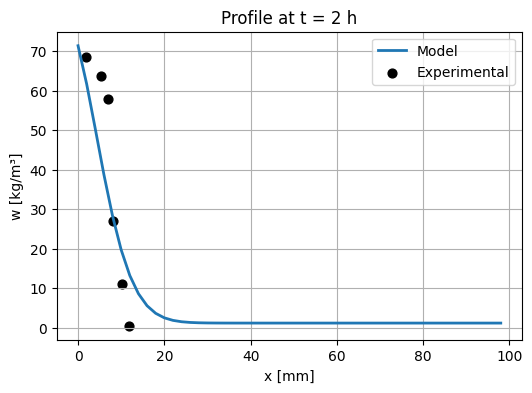

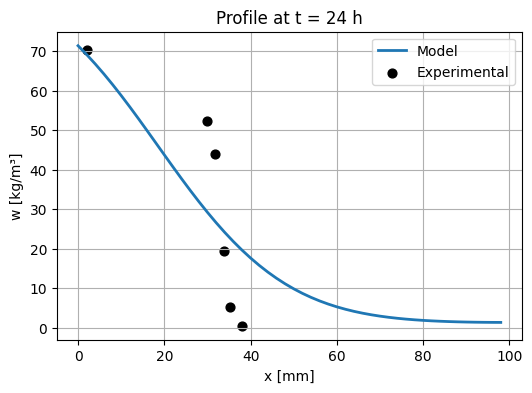

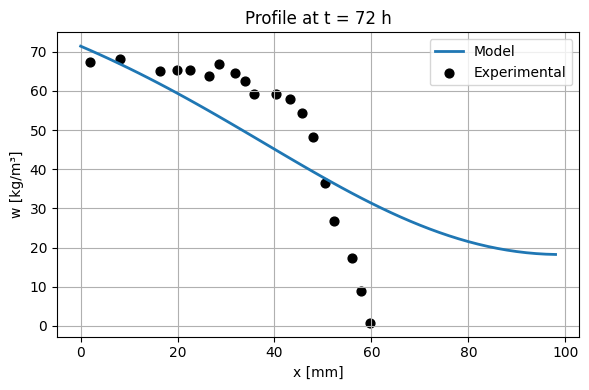

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Define the test profile parameters
phi0, T0, wc0, S00 = 0.119, 20.0, 0.45, 0.6
rho_eau = 1000.0
dx = 2e-3
dt = 60.0
Nx = 100

# Times (hours) to compare
times = [2.0, 24.0, 72.0]

for t_h in times:
    # 1) Build input tensor for this profile
    input_tensor = tf.constant([[phi0, T0, wc0, S00, t_h]], dtype=tf.float32)
    
    # 2) Compute base scales from main model
    base_scales = main_model(normalize(input_tensor))[0]
    
    # 3) Run simulation with time-dependent parameters
    x_model, w_model = simulate_model_tf_time_dependent(
        base_scales, D_network, alpha_network, n_network,
        S00, phi0, rho_eau, dx, dt, t_h * 3600.0, Nx
    )
    
    # 4) Extract experimental data for this profile and time
    grp = df_all[
        (df_all['phi'] == phi0) &
        (df_all['T'] == T0) &
        (df_all['w_c'] == wc0) &
        (df_all['S0'] == S00) &
        (df_all['t_h'] == t_h)
    ]
    x_exp = grp['x_mm'].values      # in mm
    w_exp = grp['w_exp'].values      # in kg/m³
    
    # 5) Plot model vs experimental
    plt.figure(figsize=(6,4))
    plt.plot(x_model.numpy() * 1000, w_model.numpy(), linewidth=2, label='Model')
    plt.scatter(x_exp, w_exp, color='k', marker='o', s=40, label='Experimental')
    plt.title(f"Profile at t = {int(t_h)} h")
    plt.xlabel("x [mm]")
    plt.ylabel("w [kg/m³]")
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

def simulate_numpy(D, alpha, n_shape, beta, S0=0.6, phi=0.119,
                   dx=1e-3, dt=10.0, t_h=24.0, Nx=200):
    """
    1D explicit simulation of moisture uptake w = phi * rho_eau * S
    with time-dependent capillary/vapor diffusivity.
    """
    rho_eau = 1000.0
    Pc0 = 5e6
    K_in = 1.7e-20
    eta_l = 1e-3
    Sc = 0.9
    S_cap = 0.4
    
    Tmax = t_h * 3600.0
    Nt = int(Tmax / dt)
    S = np.ones(Nx) * 0.01
    S[0] = S0
    
    for _ in range(Nt):
        S_old = S.copy()
        Sv = np.clip(S, 1e-4, 1.0)
        # vapor diffusivity
        fs = alpha + (1.0 - alpha) / (1.0 + ((1.0 - Sv) / (1.0 - Sc))**n_shape)
        Dv = fs * D
        # capillary diffusivity
        dpc = -beta * Pc0 * Sv**(-beta - 1)
        Dc = np.abs(dpc) * K_in / eta_l
        # blend
        weight = 1 / (1 + np.exp(-50.0 * (Sv - S_cap)))
        D_S = weight * Dc + (1.0 - weight) * Dv
        
        D_left = 0.5 * (D_S[:-1] + D_S[1:])
        fluxes = D_left * (S[1:] - S[:-1]) / dx
        
        dSdt = np.zeros_like(S)
        interior = (fluxes[1:] - fluxes[:-1]) / dx
        dSdt[1:-1] += interior
        dSdt[-1] += -fluxes[-1] / dx
        
        S = S_old + dt * dSdt
        S[0] = S0
    
    w = phi * rho_eau * S
    x = np.linspace(0, (Nx - 1) * dx, Nx)
    return x * 1e3, w  # x in mm, w in kg/m³

def plot_interactive(D, alpha, n_shape, beta):
    x, w = simulate_numpy(D, alpha, n_shape, beta)
    plt.figure(figsize=(6, 4))
    plt.plot(x, w, lw=2)
    plt.title("Moisture Profile w(x)")
    plt.xlabel("x [mm]")
    plt.ylabel("w [kg/m³]")
    plt.grid(True)
    plt.ylim(0, np.max(w) * 1.1)
    plt.show()

# Interactive sliders
interact(
    plot_interactive,
    D=FloatSlider(min=1e-9, max=1e-7, step=1e-9, value=1e-8, description='D [m²/s]'),
    alpha=FloatSlider(min=0.005, max=0.15, step=0.005, value=0.05, description='α'),
    n_shape=FloatSlider(min=1.2, max=8.0, step=0.2, value=2.0, description='n'),
    beta=FloatSlider(min=1.0, max=5.0, step=0.1, value=2.5, description='β')
)


interactive(children=(FloatSlider(value=1e-08, description='D [m²/s]', max=1e-07, min=1e-09, step=1e-09), Floa…

<function __main__.plot_interactive(D, alpha, n_shape, beta)>

## Choosing `dt`, `dx`, and `Nx` for Stable and Accurate Simulation

- For explicit 1D diffusion, stability requires: $dt < \frac{dx^2}{2D_{max}}$
- Smaller `dx` increases accuracy but requires smaller `dt` for stability.
- `Nx` is chosen so that the domain length $L = dx \times (Nx-1)$ covers your sample.
- Typical values: `dx` in [0.5e-3, 2e-3] m, `dt` in [10, 60] s, `Nx` in [50, 200].
- Use the largest expected $D$ for stability calculation.

In [ ]:
# Recommended dt, dx, Nx for stability and accuracy
D_max = 1e-7  # maximum expected D (m²/s)
L = 0.1       # domain length in meters (e.g., 100 mm)

dx = 1e-3     # spatial step (1 mm)
Nx = int(L / dx) + 1
dt_stable = dx**2 / (2 * D_max)

print(f"Recommended dx: {dx:.1e} m")
print(f"Recommended Nx: {Nx} (covers {L*1000:.0f} mm)")
print(f"Maximum stable dt: {dt_stable:.2f} s (for D={D_max:.1e} m²/s)")

# For accuracy, use dt <= dt_stable, and Nx >= 50
# Example: dx=1e-3, Nx=101, dt=30.0